# Supplementary figure: technical and demographic covariates and the data-driven model

Regroups panels of Figures S10, S14, S16 and of the per-TSS regression figure, redrawn from the same exported source data (no_deep cohort). Source data in `data/no_deep/`:

| panel | content | source data |
|---|---|---|
| a | AUROC of each per-sample measure alone, of classifiers trained on several measures, and of the TSS model, both tasks | `figR2_measures_bars.csv`, recomputed from `fig3_predictions.csv`, `fig3_baseline_predictions.csv`, `fig4_baseline_predictions.csv` |
| b, c | AUROC against the number of TSSs *k*, TSS model with and without the five covariates (*k* = 0: the covariates alone) | `figS14_folds.csv`, `figS14_tuned.csv`, `figS14_references.csv`, baseline predictions |
| d, e | per-TSS regression: class t adjusted for the covariates against unadjusted | `figS10_tss_regression_tss.csv`, `figS10_tss_regression_summary.csv` |
| f | Spearman correlation of the held-out posterior with each measure, within class | `figS10_correlations.csv` |
| g | within-class Spearman correlation between the within-fold ranks of the TSS model's held-out scores and those of each classifier trained on the measures | `figS10_model_vs_panels.csv` |
| h | models trained on the Cristiano cohort applied to the Jiang cohort, AUROC per comparison group | `figS16_jiang_summary.csv`, `figS16_jiang_scores.csv`, `fig4kl_external_modes_predictions.csv` |

Names used in the figure: *per-sample measures* = all eight; *covariates* = coverage, fragment count, plasma volume, age, sex; *cancer-associated measures* = fragment length, fragment GC content, cfDNA concentration; *sequencing-derived measures* = coverage, fragment count, fragment length, GC content, sex inferred from the reads.

Writes `output/no_deep/figS_covariates.png` (600 dpi) and `.pdf`. Run from `src/figures/` or from the repository root.

In [1]:
import os

# Data paths are relative to src/figures/; hop there if the kernel started elsewhere
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

COHORT = "no_deep"   # the revised cohort; every panel of this figure exists for it only
_DATA = os.path.join("data", COHORT)
_OUT = os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)


def data_path(name):
    p = os.path.join(_DATA, name)
    assert os.path.exists(p), f"{p} missing"
    return p


def out_path(name):
    return os.path.join(_OUT, name)


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import offset_copy
from sklearn.metrics import roc_auc_score
import _figstyle as fs
fs.apply()

# --- names and colors used by every panel ------------------------------------------------------------
TASKS = {"brca_crc": "BRCA/CRC", "pancan": "Pan-cancer"}                      # keys of the Fig S14 / regression exports
TASK_LONG = {"brca_crc": "BRCA/CRC versus healthy", "pancan": "Pan-cancer versus healthy"}
TASK_COLORS = {t: fs.TASK[TASK_LONG[t]] for t in TASK_LONG}                    # shared style (_figstyle)
OLD_TASK = {"brca_crc": "BRCA/CRC", "pancan": "PANCAN"}                       # task keys of the Fig S10 exports
MEASURE = {"mean_coverage": "Mean coverage", "total_fragments": "Total fragments", "plasma_volume": "Plasma volume",
           "age": "Age", "sex_female": "Sex", "fragment_length_mean": "Mean fragment length", "mean_gc": "Mean fragment GC",
           "cfdna_extracted": "cfDNA concentration", "ichorcna_tf": "ichorCNA tumor fraction",
           "sex_female_bam": "Sex (from the reads)", "stage_ordinal": "Stage (0-IV)"}
COVARIATES = ["mean_coverage", "total_fragments", "plasma_volume", "age", "sex_female"]
CANCER_ASSOCIATED = ["fragment_length_mean", "mean_gc", "cfdna_extracted"]
SEQUENCING_DERIVED = ["mean_coverage", "total_fragments", "fragment_length_mean", "mean_gc", "sex_female_bam"]
INK, MUTED = "#222222", "#666666"

# --- a: AUROC per measure, per classifier of several measures, and of the TSS model (figS10.ipynb) ---
bars_csv = pd.read_csv(data_path("figR2_measures_bars.csv"))
bars_csv["task"] = bars_csv["task"].map({v: k for k, v in OLD_TASK.items()})
assert bars_csv.groupby("task")["method"].nunique().eq(15).all()
# The CSV is rounded to four decimals (double rounding on the bar labels), so the bars are recomputed from the
# held-out scores (AUROC per outer fold, mean and population SD) and verified against the CSV.
BL_PRED = {"brca_crc": pd.read_csv(data_path("fig3_baseline_predictions.csv")),
           "pancan": pd.read_csv(data_path("fig4_baseline_predictions.csv"))}
_fig3 = pd.read_csv(data_path("fig3_predictions.csv"))
_arms = {"brca_crc": pd.concat([_fig3[(_fig3["method"] == "data_driven") & _fig3["fold"].notna()], BL_PRED["brca_crc"]], ignore_index=True),
         "pancan": BL_PRED["pancan"]}
_rows = []
for _, r in bars_csv.iterrows():
    g = _arms[r["task"]]; g = g[g["method"] == r["method"]]
    aucs = np.array([roc_auc_score(f["y_true"], f["score"]) for _, f in g.groupby("fold")])
    assert len(aucs) == 10 and abs(aucs.mean() - r["auroc_mean"]) < 6e-5 and abs(aucs.std() - r["auroc_sd"]) < 6e-5, (r["task"], r["method"])
    _rows.append({"task": r["task"], "method": r["method"], "auroc_mean": aucs.mean(), "auroc_sd": aucs.std()})
bars = pd.DataFrame(_rows)

# --- h: models trained on the Cristiano cohort applied to the Jiang cohort (Fig S16a) ---
s16_summary = pd.read_csv(data_path("figS16_jiang_summary.csv"))
s16_scores = pd.read_csv(data_path("figS16_jiang_scores.csv"))
modes_pred = pd.read_csv(data_path("fig4kl_external_modes_predictions.csv"))

# --- b, c: AUROC against the number of TSSs, with and without the five covariates (figS14_covariate_augmented.ipynb) ---
# (the five covariates alone, k = 0, come per fold from BL_PRED above)
folds = pd.read_csv(data_path("figS14_folds.csv"))
tuned = pd.read_csv(data_path("figS14_tuned.csv"))
refs = pd.read_csv(data_path("figS14_references.csv"))

# --- d, e: per-TSS regression (figS_tss_regression.ipynb) ---
reg_summary = pd.read_csv(data_path("figS10_tss_regression_summary.csv"))
reg_tss = pd.read_csv(data_path("figS10_tss_regression_tss.csv"))

# --- f: held-out posterior against each measure (figS10.ipynb) ---
corr = pd.read_csv(data_path("figS10_correlations.csv"))
corr["task"] = corr["task"].map({v: k for k, v in OLD_TASK.items()})

# --- g: rank agreement of the TSS model with each classifier trained on the measures (figS10.ipynb) ---
rank_corr = pd.read_csv(data_path("figS10_model_vs_panels.csv"))
rank_corr["task"] = rank_corr["task"].map({v: k for k, v in OLD_TASK.items()})

# the cohorts behind the panels
scalars = {"brca_crc": pd.read_csv(data_path("fig3_baseline_scalars.csv")), "pancan": pd.read_csv(data_path("fig4_baseline_scalars.csv"))}
for task, s in scalars.items():
    print(f"{TASK_LONG[task]}: {int((s['y_true'] == 0).sum())} healthy donors, {int((s['y_true'] == 1).sum())} patients")
print(f"Jiang: {int((s16_scores['y_true'] == 1).sum())} HCC, {int((s16_scores['y_true'] == 0).sum())} non-HCC "
      f"({s16_scores.loc[s16_scores['y_true'] == 0, 'control_group'].value_counts().to_dict()})")

BRCA/CRC versus healthy: 164 healthy donors, 80 patients
Pan-cancer versus healthy: 164 healthy donors, 203 patients
Jiang: 90 HCC, 135 non-HCC ({'Chronic hepatitis B': 67, 'HBV-associated cirrhosis': 36, 'Healthy': 32})


## Panels

In [2]:
# shared figure style (_figstyle); letters placed by fs.panel / fs.save


from matplotlib import patheffects


def clean(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_axisbelow(True)


ERR = {"elinewidth": 0.6, "capsize": 1.2, "capthick": 0.6, "ecolor": "0.15"}

# ---------------------------------------------------------------------------------------------------------
# a: grouped bars, one pair (BRCA/CRC, pan-cancer) per measure, classifier or model
# ---------------------------------------------------------------------------------------------------------
BAR_NAME = {"bl_mean_coverage": "Mean\ncoverage", "bl_total_fragments": "Total\nfragments", "bl_plasma_volume": "Plasma\nvolume",
            "bl_age": "Age", "bl_sex_female": "Sex", "bl_fragment_length_mean": "Mean\nfragment\nlength", "bl_mean_gc": "Mean\nfragment\nGC",
            "bl_cfdna_extracted": "cfDNA\nconcen-\ntration", "bl_ichorcna_tf": "ichorCNA\ntumor\nfraction",
            "bl_panel_technical3": "Technical\n(3)", "bl_panel_demographic": "Demo-\ngraphic (2)", "bl_panel_transfer5": "Sequencing-\nderived (5)",
            "bl_panel_techdemo5": "Covariates\n(5)", "bl_panel_all8": "All 8\nmeasures", "data_driven": "Data-\ndriven"}
BAR_MEMBERS = {"bl_panel_technical3": "coverage,\nfragments,\nplasma\nvolume", "bl_panel_demographic": "age, sex",
               "bl_panel_transfer5": "coverage,\nfragments,\nfragment\nlength,\nGC, sex",
               "bl_panel_techdemo5": "coverage,\nfragments,\nplasma\nvolume,\nage, sex",
               "bl_panel_all8": "5 covariates,\nfragment\nlength,\nGC, cfDNA"}
assert set(BAR_NAME) == set(bars["method"])
_mean_of = bars.groupby("method")["auroc_mean"].mean()
BAR_SINGLES = sorted([m for m in BAR_NAME if m.startswith("bl_") and not m.startswith("bl_panel")], key=lambda m: _mean_of[m])
BAR_PANELS = sorted([m for m in BAR_NAME if m.startswith("bl_panel")], key=lambda m: _mean_of[m])
BAR_GROUPS_A = [("One measure alone", BAR_SINGLES, 1.05), ("Classifiers trained on several measures", BAR_PANELS, 1.3),
                ("Model", ["data_driven"], 1.0)]          # (name, members, spacing of the members)
A_TOP = 1.30                                                          # y limit: value labels, the legend and the group names fit below it


def panel_measures(ax, letter):
    """AUROC (mean and SD over the 10 outer folds) of each measure alone, of the classifiers trained on several
    measures, and of the TSS model; the order within a group is by the mean of the two tasks."""
    x = 0.0; ticks, tick_m, spans = [], [], []
    width = 0.4
    for name, members, step in BAR_GROUPS_A:
        x0 = x
        for m in members:
            for off, task in zip((-0.21, 0.21), TASKS):
                r = bars[(bars["task"] == task) & (bars["method"] == m)].iloc[0]
                ax.bar(x + off, r["auroc_mean"], width=width, color=TASK_COLORS[task], yerr=r["auroc_sd"], linewidth=0, error_kw=ERR)
                ax.text(x + off, r["auroc_mean"] + r["auroc_sd"] + 0.015, f"{r['auroc_mean']:.3f}", rotation=90, ha="center", va="bottom",
                        fontsize=fs.VALUE, zorder=4)
            ticks.append(x); tick_m.append(m); x_last = x; x += step
        spans.append((name, x0 - 0.5, x_last + 0.5))
        x = x_last + 1.2
    ax.set_xticks(ticks); ax.set_xticklabels([BAR_NAME[m] for m in tick_m])
    ax.tick_params(axis="x", length=0, pad=2.5)
    trans = ax.get_xaxis_transform()
    for t_, m in zip(ticks, tick_m):
        if m in BAR_MEMBERS:                      # the members of the classifier, one line at a time (even line spacing)
            for j, line in enumerate(BAR_MEMBERS[m].split("\n")):
                ax.annotate(line, xy=(t_, 0), xycoords=trans, xytext=(0, -24 - 6.6 * j), textcoords="offset points",
                            ha="center", va="baseline", fontsize=fs.VALUE, color="0.3")
    for name, a_, b_ in spans:                    # the group names, inside the top of the axes
        ax.plot([a_ + 0.1, b_ - 0.1], [A_TOP - 0.085] * 2, color="0.35", linewidth=0.6, clip_on=False)
        ax.text((a_ + b_) / 2, A_TOP - 0.075, name, ha="center", va="bottom", fontsize=fs.SMALL)
    ax.axhline(0.5, color=fs.CHANCE, linestyle=":", linewidth=0.8, zorder=1)
    ax.set_xlim(-0.5, x_last + 0.5); ax.set_ylim(0.3, A_TOP); ax.set_yticks(np.arange(0.3, 1.01, 0.1))   # from 0.3: every bar ends above it
    ax.set_ylabel("AUROC (mean ± SD)")
    fs.value_grid(ax); clean(ax)
    ax.legend(handles=[Patch(facecolor=TASK_COLORS[t], label=TASK_LONG[t]) for t in TASKS], loc="upper left",
              bbox_to_anchor=(-0.45, A_TOP - 0.12), bbox_transform=ax.transData, ncol=2, borderaxespad=0, handlelength=1.2)
    fs.panel(ax, letter, "Single measures, classifiers and the model")
    return tick_m


# ---------------------------------------------------------------------------------------------------------
# h: models trained on the Cristiano cohort, applied to the Jiang cohort
# ---------------------------------------------------------------------------------------------------------
JIANG_GROUPS = [("all_non_hcc", "HCC versus all\n135 non-HCC"), ("Healthy", "versus 32\nhealthy"),
                ("Chronic hepatitis B", "versus 67 chronic\nhepatitis B"), ("HBV-associated cirrhosis", "versus 36\ncirrhosis")]
JIANG_SINGLES = [f"bl_{c}" for c in SEQUENCING_DERIVED]
JIANG_ARMS = ["tss", "tss_jiang_std", "tss_cov5", "cov5", "rna", "atac"] + JIANG_SINGLES + ["bl_ichorcna_tf"]
JIANG_LABELS = {"tss": "Data-driven", "tss_jiang_std": "Data-driven, standardized on Jiang et al.", "tss_cov5": "Data-driven + 5 sequencing-derived measures",
                "cov5": "5 sequencing-derived measures alone", "rna": "RNA-seq", "atac": "ATAC-seq",
                **{f"bl_{c}": MEASURE[c] for c in SEQUENCING_DERIVED}, "bl_ichorcna_tf": "ichorCNA"}
JIANG_SHORT = dict(zip(JIANG_SINGLES, ["coverage", "fragments", "length", "GC", "sex"]))
JIANG_COLORS = {"tss": fs.METHOD["Data-driven"], "tss_jiang_std": "#023858", "tss_cov5": fs.METHOD_LIGHT["Data-driven"], "cov5": "#D55E00",
                "rna": fs.METHOD["RNA-seq"], "atac": fs.METHOD["ATAC-seq"], **{m: "0.6" for m in JIANG_SINGLES}, "bl_ichorcna_tf": fs.METHOD["ichorCNA"]}


def jiang_boot_ci(y, s, n=2000, seed=0):
    """The bootstrap interval of export_figS16_jiang_arms.py (participants resampled with replacement, 2,000 times)."""
    rng = np.random.default_rng(seed); y = np.asarray(y); s = np.asarray(s); out = []
    for _ in range(n):
        b = rng.choice(len(y), len(y), replace=True)
        if y[b].min() != y[b].max():
            out.append(roc_auc_score(y[b], s[b]))
    return float(np.percentile(out, 2.5)), float(np.percentile(out, 97.5))


# arm not in the export: the TSS model standardized on the Jiang cohort itself ('clinical' mode of
# fig4kl_external_modes_predictions.csv), summarized like the exporter's arms
jiang = s16_summary[["arm", "comparison", "n_hcc", "n_ctrl", "auroc", "ci_lo", "ci_hi"]].copy()
_js = modes_pred[modes_pred["mode"] == "clinical"]
assert len(_js) == 225 and "tss_jiang_std" not in set(jiang["arm"])
_sub = {"Healthy": "Healthy", "Chronic hepatitis B": "Hepatitis B", "HBV-associated cirrhosis": "Cirrhosis"}
_rows = []
for _g, _ in JIANG_GROUPS:
    _m = (_js["y_true"] == 1) | ((_js["y_true"] == 0) if _g == "all_non_hcc" else (_js["subgroup"] == _sub[_g]))
    _y, _s = _js.loc[_m, "y_true"].to_numpy(), _js.loc[_m, "score_for_roc"].to_numpy()
    _lo, _hi = jiang_boot_ci(_y, _s)
    _rows.append({"arm": "tss_jiang_std", "comparison": _g, "n_hcc": int((_y == 1).sum()), "n_ctrl": int((_y == 0).sum()),
                  "auroc": roc_auc_score(_y, _s), "ci_lo": _lo, "ci_hi": _hi})
jiang = pd.concat([jiang, pd.DataFrame(_rows)], ignore_index=True)
assert set(JIANG_ARMS) == set(jiang["arm"])
# the pipeline mode of the same file is the exported TSS arm
_pp = modes_pred[modes_pred["mode"] == "pipeline"].set_index("sample_id")["score"]
assert np.allclose(_pp.loc[s16_scores["sample_id"]].to_numpy(), s16_scores["tss"].to_numpy(), atol=1e-9)


def panel_jiang(ax, letter):
    """AUROC for HCC against all non-HCC participants and against each comparison group, one bar per model or
    measure, with the 95% bootstrap interval."""
    x = np.arange(len(JIANG_GROUPS))
    w = 0.8 / len(JIANG_ARMS)
    order = [g for g, _ in JIANG_GROUPS]
    for i, arm in enumerate(JIANG_ARMS):
        r = jiang[jiang["arm"] == arm].set_index("comparison").loc[order]
        ax.bar(x + (i - len(JIANG_ARMS) / 2 + 0.5) * w, r["auroc"], w, linewidth=0,
               yerr=[r["auroc"] - r["ci_lo"], r["ci_hi"] - r["auroc"]], color=JIANG_COLORS[arm],
               alpha=0.5 if arm in JIANG_SINGLES else 0.9, error_kw=ERR)
        if arm in JIANG_SINGLES:                  # the five gray bars are named inside the bars of the first group
            ax.text(x[0] + (i - len(JIANG_ARMS) / 2 + 0.5) * w, 0.015, JIANG_SHORT[arm], rotation=90, ha="center", va="bottom",
                    fontsize=fs.VALUE, color=INK)
    ax.axhline(0.5, color=fs.CHANCE, linestyle=":", linewidth=0.8, zorder=1)
    ax.set_ylim(0, 1.0)
    ax.set_xticks(x); ax.set_xticklabels([l for _, l in JIANG_GROUPS]); ax.set_xlim(-0.5, len(x) - 0.5)
    ax.tick_params(axis="x", length=0)
    fs.value_grid(ax); clean(ax)
    ax.set_ylabel("AUROC (Jiang et al.)")
    handles = [Patch(facecolor=JIANG_COLORS[a], alpha=0.9, label=JIANG_LABELS[a]) for a in ["tss", "tss_jiang_std", "tss_cov5", "cov5", "rna", "atac"]]
    handles += [Patch(facecolor="0.6", alpha=0.5, label="Each sequencing-derived measure alone"),
                Patch(facecolor=JIANG_COLORS["bl_ichorcna_tf"], alpha=0.9, label=JIANG_LABELS["bl_ichorcna_tf"])]
    ax.legend(handles=handles, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.27), borderaxespad=0, handlelength=1.2, columnspacing=1.5)
    fs.panel(ax, letter, "Applied to Jiang et al.")


# ---------------------------------------------------------------------------------------------------------
# b, c: AUROC against the number of TSSs k, with and without the five covariates inside the model
# ---------------------------------------------------------------------------------------------------------
K_ARMS = {"none": ("Data-driven", fs.METHOD["Data-driven"]), "cov_techdemo5": ("Data-driven + 5 covariates", "#3B4A8C")}
COV_PANEL = "bl_panel_techdemo5"      # the five covariates alone: its own nested run on the same outer folds
K0_X, K_BREAK = 4.0, 6.5              # a log axis has no 0: k = 0 sits left of a break


def covariate_fold_aucs(task):
    """Held-out AUROC per outer fold of the classifier trained on the five covariates alone."""
    p = BL_PRED[task]
    q = p[(p["method"] == COV_PANEL) & p["score"].notna()]
    aucs = np.array([roc_auc_score(g["y_true"], g["score"] * g["orientation"].fillna(1.0)) for _, g in q.groupby("fold")])
    r = refs[(refs["task"] == task) & (refs["arm"] == "cov_techdemo5")]
    assert len(aucs) == 10 and np.isclose(aucs.mean(), r["auc_fold_mean"].iloc[0], atol=1e-6), task
    return aucs


def tuned_auc(task, arm):
    """Mean held-out AUROC with k selected in the inner loop of every outer fold."""
    t = tuned[(tuned["task"] == task) & (tuned["arm"] == arm)]
    assert len(t) == 10, (task, arm)
    return t["test_auc"].mean()


def panel_auc_vs_k(ax, task, letter, point_size=3):
    """Mean held-out AUROC against k per arm (line), the outer folds as light points; k = 0 = the five covariates
    alone (dotted level), joined to k = 10 by a dashed segment across the axis break."""
    handles = []
    for arm, (label, col) in K_ARMS.items():
        g = folds[(folds["task"] == task) & (folds["arm"] == arm)]
        m = g.groupby("k")["test_auc"].agg(["mean", "count"]).reset_index()
        assert m["count"].eq(10).all(), (task, arm)
        ax.scatter(g["k"], g["test_auc"], s=point_size, color=col, alpha=0.3, linewidths=0)
        ax.plot(m["k"], m["mean"], marker="o", color=col, linewidth=1.1, markersize=2.8)
        handles.append(Line2D([], [], color=col, marker="o", markersize=2.8, linewidth=1.1, label=f"{label} ({tuned_auc(task, arm):.3f})"))
        if arm == "cov_techdemo5":
            a = covariate_fold_aucs(task)
            ax.scatter(np.full(len(a), K0_X), a, s=point_size, color=col, alpha=0.3, linewidths=0)
            ax.plot([K0_X, m["k"].iloc[0]], [a.mean(), m["mean"].iloc[0]], color=col, linewidth=0.8, linestyle="--")
            ax.plot([K0_X], [a.mean()], marker="o", color=col, markersize=3.5)
            ax.axhline(a.mean(), color=col, linestyle=":", linewidth=0.8)
            handles.append(Line2D([], [], color=col, linestyle=":", linewidth=0.8, label=f"5 covariates alone ({a.mean():.3f})"))
    ax.set_xscale("log"); ax.set_xlim(2.9, 21000); ax.set_ylim(0.45, 1.01)
    fs.value_grid(ax)
    ax.axvline(K_BREAK, color="0.55", linewidth=0.6)
    ax.set_xticks([K0_X, 10, 100, 1000, 10000, 15000])
    ax.set_xticklabels(["0", "10", "100", "1,000", "10,000", "all"])
    _tl = ax.get_xticklabels(); _tl[4].set_ha("right"); _tl[5].set_ha("left")     # "10,000" and "all" side by side
    ax.set_xticks([x * d for d in (10, 100, 1000) for x in range(2, 10) if x * d < 21000], minor=True)
    ax.tick_params(axis="x", which="minor", length=1.5, width=0.4)
    ax.set_xlabel("Number of selected TSSs (k)")
    ax.set_ylabel("AUROC (fold mean)")
    ax.legend(handles=handles, loc="lower right", borderaxespad=0.2)
    clean(ax)
    fs.panel(ax, letter, TASK_LONG[task])


# ---------------------------------------------------------------------------------------------------------
# d, e: per-TSS regression, class t adjusted for the covariates against unadjusted
# ---------------------------------------------------------------------------------------------------------
HEX_NORM = LogNorm(vmin=1, vmax=100)
# the axis limit of figS_tss_regression.ipynb (over the unadjusted and both adjusted fits)
T_LIM = float(np.nanpercentile(np.abs(reg_tss[["t_class_unadj", "t_class_confounders", "t_class_all"]].to_numpy()), 99.98)) * 1.05


def reg_row(task, model, term="class"):
    r = reg_summary[(reg_summary["task"] == task) & (reg_summary["scope"] == "pooled") & (reg_summary["model"] == model) & (reg_summary["term"] == term)]
    assert len(r) == 1, (task, model, term)
    return r.iloc[0]


def panel_regression(ax, task, letter, ylabel=True):
    """One ordinary least-squares fit per TSS: t-statistic of the class term with the covariates in the fit against
    the t-statistic without them; hexagonal bins colored by the number of TSSs."""
    d = reg_tss[reg_tss["task"] == task]
    hb = ax.hexbin(d["t_class_unadj"], d["t_class_confounders"], gridsize=60, extent=(-T_LIM, T_LIM, -T_LIM, T_LIM),
                   norm=HEX_NORM, mincnt=1, cmap="Blues", linewidths=0)
    ax.plot([-T_LIM, T_LIM], [-T_LIM, T_LIM], color=INK, linewidth=0.6)
    ax.axhline(0, color="0.8", linewidth=0.4, zorder=0); ax.axvline(0, color="0.8", linewidth=0.4, zorder=0)
    s0, s1 = reg_row(task, "unadjusted"), reg_row(task, "confounders")
    # bottom right, below the diagonal; the shorter lines on top, where the bins come closer
    ax.text(0.99, 0.02, f"Slope {s1['slope_t_vs_unadjusted']:.2f}\n"
                        f"Sign flips: {int(s1['n_sign_flips_among_sig'])}\n"
                        f"Spearman {s1['spearman_t_vs_unadjusted']:.2f}\n"
                        f"q < 0.05: {int(s0['n_sig_q05'])} to {int(s1['n_sig_q05'])}",
            transform=ax.transAxes, va="bottom", ha="right", multialignment="right", fontsize=fs.VALUE, color=INK, linespacing=1.25,
            path_effects=[patheffects.withStroke(linewidth=1.6, foreground="white")])     # a halo where the text meets the bins
    ax.set_xlim(-T_LIM, T_LIM); ax.set_ylim(-T_LIM, T_LIM); ax.set_aspect("equal")
    ax.set_xticks([-4, -2, 0, 2, 4]); ax.set_yticks([-4, -2, 0, 2, 4])
    clean(ax)
    ax.set_xlabel("Class t (unadjusted)")
    if ylabel:
        ax.set_ylabel("Class t (adjusted)")
    else:
        ax.tick_params(labelleft=False)
    fs.panel(ax, letter, f"{TASKS[task]} task")
    if not ylabel:
        ax._left_title.set_x(0.09)          # clear of the letter (no tick labels on this axis)
    return hb


# ---------------------------------------------------------------------------------------------------------
# f: Spearman correlation of the held-out posterior with each measure, within class
# ---------------------------------------------------------------------------------------------------------
CORR_ROWS = COVARIATES + CANCER_ASSOCIATED + ["ichorcna_tf", "stage_ordinal"]
CORR_COLS = [(task, scope) for task in TASKS for scope in ("healthy only", "cancer only")]


def corr_cell(task, scope, measure):
    r = corr[(corr["task"] == task) & (corr["scope"] == scope) & (corr["covariate"] == measure)]
    return (r["rho"].iloc[0], r["q"].iloc[0]) if len(r) else (np.nan, 1.0)


def panel_correlations(ax, cax, letter):
    """Spearman correlation between the TSS model's held-out posterior and each measure, among the healthy donors
    and among the patients of each task; star = Benjamini-Hochberg q < 0.05 (within task, as exported)."""
    mat = np.full((len(CORR_ROWS), len(CORR_COLS)), np.nan); qm = np.ones_like(mat)
    for si, (task, scope) in enumerate(CORR_COLS):
        for ci, col in enumerate(CORR_ROWS):
            mat[ci, si], qm[ci, si] = corr_cell(task, scope, col)
    cmap = plt.get_cmap("RdBu_r").copy(); cmap.set_bad("#EFEFEF")
    im = ax.imshow(np.ma.masked_invalid(mat), cmap=cmap, vmin=-1, vmax=1, aspect="auto")
    for ci in range(len(CORR_ROWS)):
        for si in range(len(CORR_COLS)):
            if np.isnan(mat[ci, si]):
                ax.text(si, ci, "n/a", ha="center", va="center", fontsize=fs.VALUE, color="gray"); continue
            ax.text(si, ci, f"{mat[ci, si]:+.2f}{'*' if qm[ci, si] < 0.05 else ''}", ha="center", va="center", fontsize=fs.VALUE,
                    color="white" if abs(mat[ci, si]) > 0.55 else "black")
    ax.set_xticks(range(len(CORR_COLS)))
    ax.set_xticklabels(["Healthy" if s == "healthy only" else "Cancer" for _, s in CORR_COLS])
    ax.tick_params(length=0)
    for i, task in enumerate(TASKS):          # the task under each pair of columns
        ax.annotate(TASKS[task], xy=(0.25 + 0.5 * i, 0), xycoords="axes fraction", xytext=(0, -15), textcoords="offset points",
                    ha="center", va="top", fontsize=fs.SMALL)
        ax.plot([0.5 * i + 0.03, 0.5 * i + 0.47], [0, 0], transform=offset_copy(ax.transAxes, fig=ax.figure, y=-13, units="points"),
                color="0.35", linewidth=0.6, clip_on=False)
    ax.set_yticks(range(len(CORR_ROWS))); ax.set_yticklabels([MEASURE[c] for c in CORR_ROWS], color=INK)
    for side in ax.spines.values():
        side.set_visible(False)
    ax.axvline(1.5, color="white", linewidth=1.5)
    cb = ax.figure.colorbar(im, cax=cax)
    cb.set_label("Spearman correlation", labelpad=2); cb.outline.set_visible(False)
    cb.set_ticks([-1, -0.5, 0, 0.5, 1])
    fs.panel(ax, letter, "Posterior and each measure")
    ax._left_title.set_x(-0.62)                     # the title starts above the row names
    return mat


# ---------------------------------------------------------------------------------------------------------
# g: does the TSS model rank the samples like a classifier trained on the measures?
# ---------------------------------------------------------------------------------------------------------
# the key is the classifier's name in figS10_model_vs_panels.csv
RANK_ROWS = [("All 8", "bl_panel_all8"), ("Technical panel", "bl_panel_technical3"), ("Technical + demographic panel", "bl_panel_techdemo5"),
             ("Demographic panel", "bl_panel_demographic"), ("Cohort-transferable panel", "bl_panel_transfer5")]
RANK_NAME = {m: BAR_NAME[m].replace("-\n", "-").replace("\n", " ") for _, m in RANK_ROWS}      # the names of panel a, on one line
RANK_NAME["bl_panel_demographic"] = "Demographic (2)"     # (panel a splits this name with a hyphen)


def rank_cell(task, method, scope):
    """Spearman correlation between the within-fold ranks of the TSS model's and the classifier's held-out scores,
    among the healthy donors (scope 'healthy') or the patients (scope 'cancer') of the task."""
    key = next(k for k, m in RANK_ROWS if m == method)
    r = rank_corr[(rank_corr["task"] == task) & (rank_corr["panel"] == key)]
    assert len(r) == 1, (task, method)
    return float(r[scope].iloc[0])


def panel_rank_agreement(ax, letter):
    """One pair of markers per classifier and task: filled = within healthy donors, open = within cancers."""
    for yi, (_, m) in enumerate(RANK_ROWS):
        for task, off in zip(TASKS, (-0.17, 0.17)):
            h_, c_ = rank_cell(task, m, "healthy"), rank_cell(task, m, "cancer")
            ax.plot([h_, c_], [yi + off] * 2, color=TASK_COLORS[task], linewidth=0.8, alpha=0.6, zorder=1)
            ax.scatter(h_, yi + off, s=11, color=TASK_COLORS[task], edgecolors="black", linewidths=0.4, zorder=3)
            ax.scatter(c_, yi + off, s=11, facecolors="white", edgecolors=TASK_COLORS[task], linewidths=1.0, zorder=3)
    ax.set_yticks(range(len(RANK_ROWS))); ax.set_yticklabels([RANK_NAME[m].replace("Sequencing-derived", "Sequencing-\nderived") for _, m in RANK_ROWS], color=INK)
    ax.tick_params(axis="y", length=0)
    ax.invert_yaxis()
    ax.axvline(0, color="0.4", linewidth=0.6); ax.set_xlim(-0.6, 0.6); ax.set_xticks([-0.5, 0.0, 0.5])
    ax.set_xlabel("Spearman correlation")
    ax.legend(handles=[Line2D([], [], marker="o", linestyle="", markerfacecolor="0.3", markeredgecolor="black", markeredgewidth=0.4, markersize=3.5, label="Within healthy"),
                       Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor="0.3", markeredgewidth=1.0, markersize=3.5, label="Within cancers")],
              loc="upper right", bbox_to_anchor=(1.02, -0.33), ncol=2, borderaxespad=0, columnspacing=1.0, handletextpad=0.2, handlelength=1.0)
    fs.value_grid(ax, axis="x"); clean(ax)
    fs.panel(ax, letter, "Agreement with classifiers")
    ax._left_title.set_x(-0.62)

## Assemble the figure

saved output\no_deep\figS_covariates.png/.pdf at 178 x 183 mm


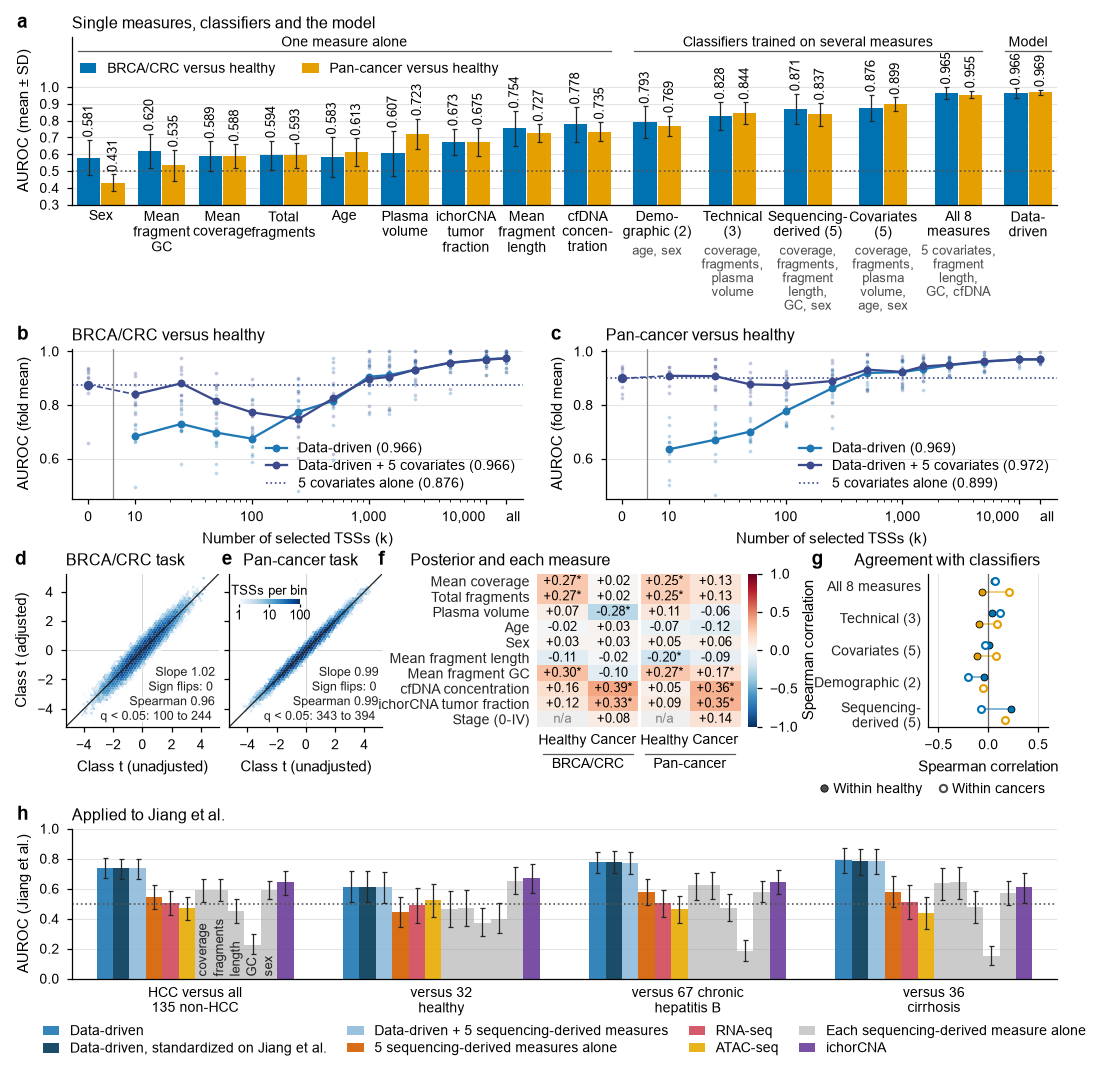

In [3]:
# shared figure style, every axes placed in inches from the top of the figure
W = fs.WIDTH
# the Jiang et al. panel (h) is the bottom row
ROWS = {          # (top of the axes, height), inches from the top of the figure
    "a": (0.24, 1.12), "cd": (2.32, 1.0), "efgh": (3.82, 1.02), "b": (5.52, 1.0)}
H = 7.20
fig = plt.figure(figsize=(W, H))


def axes_at(left, row, width, height=None):
    top, h = ROWS[row]
    h = h if height is None else height
    return fig.add_axes([left / W, (H - top - h) / H, width / W, h / H])


L, R = 0.40, 0.04                         # left margin for the y labels, right margin
# --- a, b: full width ----------------------------------------------------------------------------------
ax_a = axes_at(L, "a", W - L - R)
bar_order = panel_measures(ax_a, "a")
ax_b = axes_at(L, "b", W - L - R)   # Jiang et al., bottom row
panel_jiang(ax_b, "h")

# --- c, d ----------------------------------------------------------------------------------------------
GAP_CD = 0.55
w_cd = (W - L - R - GAP_CD) / 2
ax_c, ax_d = axes_at(L, "cd", w_cd), axes_at(L + w_cd + GAP_CD, "cd", w_cd)
panel_auc_vs_k(ax_c, "brca_crc", "b")
panel_auc_vs_k(ax_d, "pancan", "c")

# --- e, f, g, h ----------------------------------------------------------------------------------------
SQ = ROWS["efgh"][1]                       # e and f are square
x_e = 0.36; x_f = x_e + SQ + 0.07
ax_e, ax_f = axes_at(x_e, "efgh", SQ), axes_at(x_f, "efgh", SQ)
panel_regression(ax_e, "brca_crc", "d")
hb = panel_regression(ax_f, "pancan", "e", ylabel=False)
cax_f = ax_f.inset_axes([0.06, 0.8, 0.4, 0.035])        # the color scale sits in the empty upper left corner of f
cb = fig.colorbar(hb, cax=cax_f, orientation="horizontal")
cb.set_ticks([1, 10, 100]); cb.set_ticklabels(["1", "10", "100"]); cb.minorticks_off()
cb.ax.tick_params(labelsize=fs.VALUE, length=1.5, pad=1)
cb.ax.set_title("TSSs per bin", fontsize=fs.VALUE, pad=2, loc="center")
cb.outline.set_visible(False)
x_g = x_f + SQ + 1.03; w_g = 1.36
ax_g, cax_g = axes_at(x_g, "efgh", w_g), axes_at(x_g + w_g + 0.05, "efgh", 0.06)
corr_matrix = panel_correlations(ax_g, cax_g, "f")
x_h = x_g + w_g + 0.05 + 0.06 + 0.42 + 0.72
ax_h = axes_at(x_h, "efgh", W - 0.1 - x_h)
panel_rank_agreement(ax_h, "g")

fs.save(fig, out_path("figS_covariates"))
plt.show()

## Numbers and checks

In [4]:
def check(name, value, expected, decimals=3):
    ok = round(float(value), decimals) == expected
    print(f"{'ok  ' if ok else 'DIFF'} {name}: {value:.4f} (expected {expected})")
    return ok


results = []
# --- the cohorts ---------------------------------------------------------------------------------------
n = {t: (int((s["y_true"] == 0).sum()), int((s["y_true"] == 1).sum())) for t, s in scalars.items()}
print(f"Cristiano, revised cohort: {n['brca_crc'][0]} healthy donors, {n['brca_crc'][1]} BRCA/CRC, {n['pancan'][1]} cancers in total; "
      f"{reg_tss.groupby('task')['tss_window_index'].nunique().to_dict()} TSSs")
assert n["brca_crc"] == (164, 80) and n["pancan"] == (164, 203)
assert reg_tss.groupby("task")["tss_window_index"].nunique().eq(14221).all() and reg_summary["n_tss"].eq(14221).all()
assert int(folds["n_tss_available"].max()) == 14221
n_j = (int((s16_scores["y_true"] == 1).sum()), int((s16_scores["y_true"] == 0).sum()))
print(f"Jiang: {n_j[0]} HCC, {n_j[1]} non-HCC")
assert n_j == (90, 135)
assert jiang.set_index(["arm", "comparison"]).loc[[(a, "all_non_hcc") for a in JIANG_ARMS], ["n_hcc", "n_ctrl"]].eq([90, 135]).all().all()

# --- a ---------------------------------------------------------------------------------------------------
B = bars.set_index(["task", "method"])["auroc_mean"]
print("\nPanel a, AUROC (mean over the 10 outer folds), in the order drawn:")
print(bars.pivot(index="method", columns="task", values="auroc_mean").loc[bar_order].rename(columns=TASKS).round(3).to_string())
results += [check("a, five-covariate classifier, BRCA/CRC", B["brca_crc", "bl_panel_techdemo5"], 0.876),
            check("a, five-covariate classifier, pan-cancer", B["pancan", "bl_panel_techdemo5"], 0.899),
            check("a, TSS model, BRCA/CRC", B["brca_crc", "data_driven"], 0.966),
            check("a, TSS model, pan-cancer", B["pancan", "data_driven"], 0.969)]

# --- h ---------------------------------------------------------------------------------------------------
print("\nPanel h, HCC against all non-HCC participants:")
J = jiang[jiang["comparison"] == "all_non_hcc"].set_index("arm")["auroc"]
for arm, e in {"tss": 0.741, "tss_jiang_std": 0.740, "tss_cov5": 0.735, "cov5": 0.546, "rna": 0.503, "atac": 0.470}.items():
    results.append(check(JIANG_LABELS[arm], J[arm], e))
print(jiang.pivot(index="arm", columns="comparison", values="auroc").loc[JIANG_ARMS, [g for g, _ in JIANG_GROUPS]].rename(index=JIANG_LABELS).round(3).to_string())

# --- b, c ------------------------------------------------------------------------------------------------
print("\nPanels b, c:")
for task, (e_cov, e_tss, e_both) in {"brca_crc": (0.876, 0.966, 0.966), "pancan": (0.899, 0.969, 0.972)}.items():
    results += [check(f"{TASKS[task]}, five covariates alone (k = 0)", covariate_fold_aucs(task).mean(), e_cov),
                check(f"{TASKS[task]}, TSS model at the selected k", tuned_auc(task, "none"), e_tss),
                check(f"{TASKS[task]}, TSS + 5 covariates at the selected k", tuned_auc(task, "cov_techdemo5"), e_both)]
    # the same runs are behind panel a
    assert abs(covariate_fold_aucs(task).mean() - B[task, "bl_panel_techdemo5"]) < 1e-4 and abs(tuned_auc(task, "none") - B[task, "data_driven"]) < 1e-4
    t = tuned[tuned["task"] == task]
    print(f"   {TASKS[task]}: k selected per fold: " + "; ".join(
        f"{K_ARMS[a][0]} {t[t['arm'] == a]['k_selected'].value_counts().sort_index().to_dict()}" for a in K_ARMS))

# --- d, e ------------------------------------------------------------------------------------------------
print("\nPanels d, e (covariates in the fit: " + ", ".join(
    reg_summary[(reg_summary["model"] == "confounders") & (reg_summary["scope"] == "pooled") & (reg_summary["term"] != "class")]["term"].unique()) + "):")
for task, e_rho in {"brca_crc": 0.96, "pancan": 0.99}.items():
    s0, s1 = reg_row(task, "unadjusted"), reg_row(task, "confounders")
    results.append(check(f"{TASKS[task]}, Spearman of adjusted against unadjusted class t", s1["spearman_t_vs_unadjusted"], e_rho, 2))
    print(f"   slope {s1['slope_t_vs_unadjusted']:.2f}; significant TSSs {int(s0['n_sig_q05'])} to {int(s1['n_sig_q05'])}; "
          f"{int(s1['n_sign_flips_among_sig'])} sign flips; {int(s1['n_samples'])} samples")

# --- f ---------------------------------------------------------------------------------------------------
print("\nPanel f:")
for task, e_rho in {"brca_crc": 0.27, "pancan": 0.25}.items():
    rho, q = corr_cell(task, "healthy only", "mean_coverage")
    results.append(check(f"{TASKS[task]}, within healthy donors, posterior against mean coverage (q = {q:.2g})", rho, e_rho, 2))
print(pd.DataFrame(corr_matrix, index=[MEASURE[c] for c in CORR_ROWS], columns=[f"{TASKS[t]}, {s}" for t, s in CORR_COLS]).round(2).to_string())

# --- g ---------------------------------------------------------------------------------------------------
print("\nPanel g, Spearman correlation between the within-fold ranks of the TSS model and of each classifier:")
rank_table = pd.DataFrame({f"{TASKS[t]}, within {'healthy donors' if s == 'healthy' else 'cancers'}": [rank_cell(t, m, s) for _, m in RANK_ROWS]
                           for t in TASKS for s in ("healthy", "cancer")}, index=[RANK_NAME[m] for _, m in RANK_ROWS])
print(rank_table.round(3).to_string())
for name in ("Covariates (5)", "All 8 measures"):
    print(f"   {name}: " + "; ".join(f"{c} {v:+.3f}" for c, v in rank_table.loc[name].items()))
_cov = rank_table.loc["Covariates (5)"]
ok = bool(_cov.between(-0.13, 0.08).all())
print(f"{'ok  ' if ok else 'DIFF'} Covariates (5): all four values between -0.13 and +0.08 (min {_cov.min():+.3f}, max {_cov.max():+.3f}; expected -0.12 to +0.07)")
results.append(ok)

assert all(results), "a value differs from the one expected"
print(f"\nall {len(results)} checks passed")

Cristiano, revised cohort: 164 healthy donors, 80 BRCA/CRC, 203 cancers in total; {'brca_crc': 14221, 'pancan': 14221} TSSs
Jiang: 90 HCC, 135 non-HCC

Panel a, AUROC (mean over the 10 outer folds), in the order drawn:
task                     BRCA/CRC  Pan-cancer
method                                       
bl_sex_female               0.581       0.431
bl_mean_gc                  0.620       0.535
bl_mean_coverage            0.589       0.588
bl_total_fragments          0.594       0.593
bl_age                      0.583       0.613
bl_plasma_volume            0.607       0.723
bl_ichorcna_tf              0.673       0.675
bl_fragment_length_mean     0.754       0.727
bl_cfdna_extracted          0.778       0.735
bl_panel_demographic        0.793       0.769
bl_panel_technical3         0.828       0.844
bl_panel_transfer5          0.871       0.837
bl_panel_techdemo5          0.876       0.899
bl_panel_all8               0.965       0.955
data_driven                 0.966       0.969